# Chapter 8: Bandits in Production: Delays, Proxies and Guardrails

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Bandits in Production: Delays, Proxies and Guardrails](https://books.sugiv.fyi/lift/bandits-production.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import parlo, production as P, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


def lost(journey):
    return journey.regret[:, -1].mean()


SEED = 1
fixed = P.simulate(P.fixed_split, seed=SEED)
opens = P.simulate(P.thompson_opens, seed=SEED)
lessons = P.simulate(P.thompson_lessons, seed=SEED)

glue_num("fixed_lost", lost(fixed))
glue_num("opens_lost", lost(opens))
glue_num("lessons_lost", lost(lessons))
glue_num("opens_unsubs", opens.unsubs.mean())
glue_num("lessons_unsubs", lessons.unsubs.mean())
glue_num("unsub_ratio", opens.unsubs.mean() / lessons.unsubs.mean())

Here's the finding first. When I pointed Parlo's reminder bandit at push **opens**, the fast and plentiful signal, it did worse than not using a bandit at all. Over 30 days it lost about **595 lessons**, against 542 for a plain even split. It also caused **3.4× the unsubscribes**, because it fell for a clickbait message. Pointed at **completed lessons**, the signal that matters but arrives a day late, it lost only 120.

Chapter 7's bandit lived in a tidy world: one send at a time, an instant reward, no rules. Production is messier in four ways, and this chapter takes them one at a time:

1. **Batches:** beliefs update once a day, not after every send.
2. **Delays:** the outcome you care about shows up later than the send.
3. **Proxies:** a fast signal tempts you to optimise it instead.
4. **Rules:** some messages are off-limits for some learners, and some must be switched off entirely.

## The case: five reminders, two speeds

Parlo now has five reminder messages. Each send produces two signals:

- **Opened?** Known within minutes.
- **Finished a lesson within 24 hours?** Known the next day. This is what Parlo actually cares about.

Two messages only make sense for learners who have a streak going, which is about 60% of them. And one of those, "Streak DYING!!", is clickbait: it gets opened a lot, but few of those opens turn into a lesson, and it annoys people into turning notifications off.

In [3]:
pd.DataFrame([{
    "Message": m.name,
    "Open rate": m.open_rate,
    "Lesson | opened": m.complete_given_open,
    "Lesson rate": m.lesson_rate,
    "Unsubscribe rate": m.unsub_rate,
    "Needs a streak": "yes" if m.needs_streak else "",
} for m in P.MESSAGES]).set_index("Message")

,Open rate,Lesson | opened,Lesson rate,Unsubscribe rate,Needs a streak
Message,,,,,
Plain nudge,0.30,0.300,0.090,0.002,
Streak at risk,0.35,0.300,0.105,0.002,yes
Juno says hi,0.32,0.375,0.120,0.002,
Progress recap,0.25,0.400,0.100,0.002,
Streak DYING!!,0.50,0.180,0.090,0.012,yes


"Juno says hi" is the best message for everyone, at a 12% lesson rate. "Streak DYING!!" has the *highest open rate* and one of the *lowest lesson rates*. Keep an eye on it.

Each simulated world runs for 30 days at 1,000 reminders a day, and I average over 200 worlds. Regret is counted in **lessons lost**: how many fewer lessons we got than if every learner had received the best message they were eligible for.

## Batches: why Thompson sampling survives production

Real systems don't update after every send. They collect a day's outcomes, update once, and use the same beliefs for the next 1,000 sends. That's harmless for some strategies and a disaster for others.

In [4]:
ucb = P.simulate(P.ucb_lessons, seed=SEED)

pd.DataFrame({
    "lessons lost over 30 days": [lost(fixed), lost(ucb), lost(lessons)],
}, index=["Even split", "UCB1 (daily updates)", "Thompson (daily updates)"]).round(0)

,lessons lost over 30 days
Even split,542.0
UCB1 (daily updates),445.0
Thompson (daily updates),120.0


In [5]:
glue_num("ucb_lost", lost(ucb))
glue_num("ucb_vs_ts", lost(ucb) / lost(lessons))

UCB1 loses 445 lessons, about 3.7× as many as Thompson. The reason is simple once you see it. UCB is **deterministic**: given the same beliefs, it computes the same scores, so all 1,000 sends in a day go to the same message (subject to eligibility). If that message is wrong, you lose a whole day. The next day the scores swing to another message, and you lose a day there too.

Thompson is **random**: every send draws fresh guesses, so a day's batch is automatically spread across the messages in proportion to how likely each is to be the best. Batching barely hurts it. This, more than any theorem, is why most production bandits are Thompson sampling.

## Delays: what waiting costs

Lesson outcomes arrive a day after the send. Some outcomes take longer: a 7-day retention metric is known only a week later. Here's what the delay costs Thompson sampling on lessons.

In [6]:
delays = [0, 1, 3, 7]
by_delay = {d: P.simulate(P.thompson_lessons, delay=d, seed=SEED) for d in delays}
pd.DataFrame({"lessons lost": [lost(j) for j in by_delay.values()]},
             index=pd.Index(delays, name="delay (days)")).round(0)

,lessons lost
delay (days),
0,106.0
1,120.0
3,150.0
7,219.0


In [7]:
glue_num("d0_lost", lost(by_delay[0]))
glue_num("d7_lost", lost(by_delay[7]))

A week's delay roughly doubles the lessons lost, from 106 to 219. For a whole week the bandit is flying blind and sending from its day-zero beliefs. That's still far better than the even split, but it's the price that makes fast proxies so tempting.

## Proxies: the clickbait trap

Opens are known in minutes, so why not optimise opens?

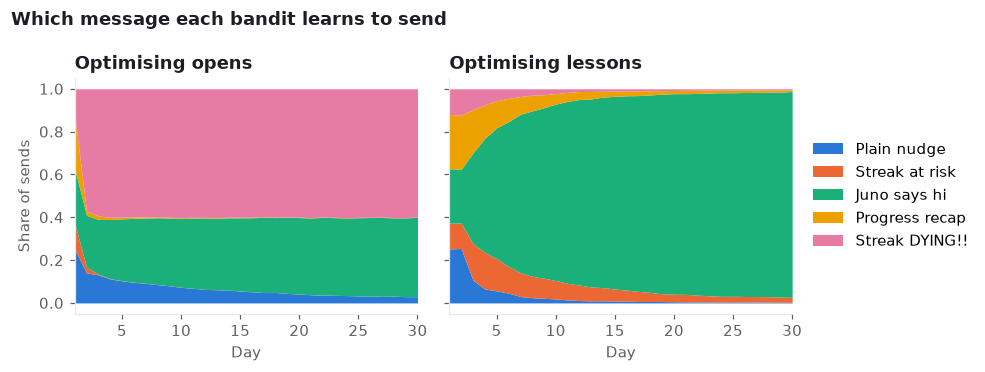

In [8]:
def share_plot(journeys, title):
    fig, axes = plt.subplots(1, len(journeys), figsize=(9, 3.4), sharey=True)
    for ax, (label, j) in zip(axes, journeys.items()):
        bottom = np.zeros(j.share.shape[0])
        for i, name in enumerate(P.NAMES):
            colour = style.SERIES[i] if i < 4 else "#e87ba4"
            ax.fill_between(np.arange(1, len(bottom) + 1), bottom, bottom + j.share[:, i],
                            color=colour, linewidth=0, label=name)
            bottom = bottom + j.share[:, i]
        ax.set(title=label, xlabel="Day")
        ax.set_xlim(1, len(bottom))
        ax.grid(False)
    axes[0].set_ylabel("Share of sends")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", color=style.INK)
    fig.tight_layout()
    plt.show()

share_plot({"Optimising opens": opens, "Optimising lessons": lessons},
           "Which message each bandit learns to send")

The opens bandit does exactly what it was told. It finds the message people open most, "Streak DYING!!", and sends it to every learner with a streak. That message has a 9% lesson rate, against 12% for "Juno says hi". So the bandit converges confidently onto a loser, and it ends up behind the even split. It also drives 233 unsubscribes against 68 for the lessons bandit.

**A bandit is an optimiser, and optimisers find the gap between what you measure and what you mean.** Opens and lessons agree on most messages. They disagree on exactly the one that was designed to game opens.

### Using a fast proxy honestly

The better way to use opens is to **factor** the reward instead of replacing it:

$$P(\text{lesson}) = P(\text{open}) \times P(\text{lesson} \mid \text{open}).$$

The first factor is learned from today's opens. The second is learned from opens whose outcome has resolved. The product is still the true lesson rate, so the bandit can't be fooled by clickbait. And it gets the open-rate part of the evidence a day early (a week early at a 7-day delay).

In [9]:
two_stage = {d: P.simulate(P.thompson_two_stage, delay=d, seed=SEED) for d in [1, 7]}
pd.DataFrame({
    "lessons only": [lost(by_delay[d]) for d in [1, 7]],
    "factored (opens x lesson | open)": [lost(two_stage[d]) for d in [1, 7]],
}, index=pd.Index([1, 7], name="delay (days)")).round(0)

,lessons only,factored (opens x lesson | open)
delay (days),,
1,120.0,116.0
7,219.0,222.0


The factored reward is correct, but at Parlo it makes no real difference: a few lessons better at a one-day delay, a few worse at seven. That surprised me at first, and it's worth understanding. Parlo's messages differ mostly in what happens *after* the open, and that part is still delayed. The fast factor tells the bandit little it needs.

Now take a world where the messages differ mostly in how often they're opened, and what happens after the open is about the same for all of them. To make the delay bite, this world has 100 sends a day for 60 days and a 7-day delay:

In [10]:
aligned = [P.Message(m.name, m.open_rate, 0.33, 0.002, m.needs_streak) for m in P.MESSAGES]
kw = dict(delay=7, per_day=100, days=60, seed=SEED, messages=aligned)
a_lessons = P.simulate(P.thompson_lessons, **kw)
a_two = P.simulate(P.thompson_two_stage, **kw)
glue_num("aligned_gain", 100 * (1 - lost(a_two) / lost(a_lessons)))
pd.DataFrame({"lessons lost": [lost(a_lessons), lost(a_two)]},
             index=["lessons only", "factored"]).round(0)

,lessons lost
lessons only,64.0
factored,53.0


Here the factored reward cuts lessons lost by about 17%. **A proxy helps exactly as much as it carries the signal you need**, and you can check that before relying on it:

- **Rank check:** on resolved data, do the messages rank the same way by open rate as by lesson rate? If the top message by opens isn't the top message by lessons, the proxy is lying about the decision you're making.
- **Ratio check:** does $P(\text{lesson} \mid \text{open})$ vary a lot between messages? If it does, the proxy alone is dangerous, and the slow factor is where the decision is made.

This is the same idea JustAI describes in the Better Mortgage case study (JustAI, 2026): lean on clicks as an early signal while rate locks trickle in, but rank on locks. The early signal speeds learning up. It never gets to decide on its own.

## Rules: eligibility and guardrails

Two kinds of rules show up in every real system.

**Eligibility** is a hard filter applied before the bandit chooses. Parlo never sends a streak message to someone without a streak. The simulator already does this: ineligible messages are simply removed from that learner's options, and the bandit chooses among the rest. Regret is measured against the best message *that learner* could have received. Masking is the simplest constraint and the most common one. Frequency caps, quiet hours and legal rules all work the same way.

**Guardrails** are softer and learned. Parlo decides that any message which probably makes more than 0.6% of learners turn off notifications should be switched off. "Probably" means: under a Beta posterior on the unsubscribe rate, there's at least a 95% chance the rate is above the limit.

In [11]:
g = P.UnsubGuardrail(limit=0.006, confidence=0.95)
guarded = P.simulate(P.thompson_opens, guardrail=g, seed=SEED)
off = guarded.switched_off_day[:, P.NAMES.index("Streak DYING!!")]

pd.DataFrame({
    "lessons lost": [lost(opens), lost(guarded)],
    "unsubscribes": [opens.unsubs.mean(), guarded.unsubs.mean()],
}, index=["optimising opens", "optimising opens + guardrail"]).round(0)

,lessons lost,unsubscribes
optimising opens,595.0,233.0
optimising opens + guardrail,327.0,69.0


In [12]:
glue_num("off_share", 100 * (off >= 0).mean())
glue_num("off_day", np.median(off[off >= 0]) + 1)
healthy = [i for i, name in enumerate(P.NAMES) if name != "Streak DYING!!"]
glue_num("healthy_off", 100 * (guarded.switched_off_day[:, healthy] >= 0).any(axis=1).mean())

The guardrail switches "Streak DYING!!" off in 100% of worlds, typically by the end of day 2. It sometimes catches a healthy message by bad luck: in 2.5% of worlds it switches one off too. Even the badly specified opens bandit becomes much safer. A guardrail is not a substitute for the right reward, though. The opens bandit with a guardrail still loses more lessons than the lessons bandit without one. **Guardrails stop harm; the reward decides what's good.**

<details>
<summary><b>Under the hood: the guardrail test</b></summary>

With $u$ unsubscribes out of $n$ sends and a flat prior, the unsubscribe rate $q$ has posterior $\mathrm{Beta}(1+u,\ 1+n-u)$. The guardrail fires when

$$P(q > 0.006 \mid \text{data}) = 1 - F_{\mathrm{Beta}(1+u,\,1+n-u)}(0.006) > 0.95,$$

which is `scipy.stats.beta.sf(0.006, 1 + u, 1 + n - u) > 0.95`. Because the check runs every day, the true false-alarm rate is higher than 5%. For a guardrail that's usually the right trade, since a wrongly paused message costs little. For a launch decision it isn't; Chapter 5 covers how to peek safely.

</details>

## When the world changes

Messages wear out. Say "Juno says hi" works brilliantly for 20 days, then learners get used to it and its lesson-given-open rate drops from 37.5% to 25%. The best message is now a different one. A bandit that weighs all its history equally is slow to notice, because it has 20 days of evidence that Juno is great.

The fix is to **forget a little every day**: multiply all counts by a discount factor $\gamma$ before adding the new day's data. Evidence from $k$ days ago then counts $\gamma^k$ as much as today's.

In [13]:
base = P.Rates.of()

def wears_out(day):
    r = P.Rates(base.open.copy(), base.complete_given_open.copy(), base.unsub.copy())
    if day >= 20:
        r.complete_given_open[P.NAMES.index("Juno says hi")] = 0.25
    return r

rows = []
for gamma in [1.0, 0.95, 0.9, 0.8]:
    j = P.simulate(P.thompson_lessons, days=40, rates_on_day=wears_out,
                   discount=gamma, seed=SEED)
    rows.append({"discount": gamma, "lost, days 1-20": j.regret[:, 19].mean(),
                 "lost, days 21-40": j.regret[:, -1].mean() - j.regret[:, 19].mean(),
                 "lost, total": j.regret[:, -1].mean()})
pd.DataFrame(rows).set_index("discount").round(0)

,"lost, days 1-20","lost, days 21-40","lost, total"
discount,,,
1.00,111.0,308.0,419.0
0.95,124.0,241.0,365.0
0.90,144.0,196.0,340.0
0.80,174.0,164.0,338.0


Forgetting has a price. Before the change, a forgetful bandit throws away good evidence and explores more than it needs to. After the change, it recovers much faster. Over the 40 days, a discount of 0.8 to 0.9 (evidence half-forgotten in a few days to a week) beats no forgetting comfortably; those two are effectively tied. My rule of thumb is to pick the discount so that the evidence half-life matches how fast your content really goes stale. A weekly-changing push campaign wants roughly 0.9; a pricing page that changes yearly wants 1.0.

## Juno: rules and delays for an agent

Everything above carries over to routing Juno's lessons between LLMs (Chapter 7), with one change in emphasis: for agents, **the eligibility rules are often about latency and cost, not about who the learner is**.

In [14]:
latency_p95 = {"large": 2.8, "medium": 1.1, "small": 0.4}   # seconds
surfaces = {"Chat lesson": 5.0, "Voice lesson": 1.5}           # latency budget
net_value = dict(zip([m.name for m in parlo.JUNO_MODELS], parlo.juno_rewards()))

pd.DataFrame({
    surface: {name: ("allowed" if latency_p95[name] <= budget else "masked")
              for name in latency_p95}
    for surface, budget in surfaces.items()
}).assign(**{"net value per lesson": pd.Series(net_value)})

,Chat lesson,Voice lesson,net value per lesson
large,allowed,masked,0.058
medium,allowed,allowed,0.068
small,allowed,allowed,0.061


In voice lessons, the large model breaks the 1.5-second budget, so it's masked exactly like a streak message for a learner without a streak. The bandit chooses among what's left. Juno's other production issues map one to one:

| Production issue | Parlo reminders | Juno routing |
|---|---|---|
| Fast proxy | Push opened | Learner keeps chatting past the first turn |
| Delayed outcome | Lesson finished within 24 h | Lesson completed; learner's rating days later |
| Clickbait trap | "Streak DYING!!" | A model that flatters the learner: long chats, little learning |
| Hard constraint | Needs a streak | p95 latency budget per surface |
| Guardrail | Unsubscribe rate | Complaint or safety-flag rate |
| Wear-out | Message fatigue | A new model version ships; old evidence goes stale |

The last row is the one teams forget. When a provider updates a model behind the same name, the bandit's history for that arm describes a different model. **Reset or heavily discount an arm whenever the thing behind it changes.**

> **In the wild**
>
> Better Mortgage's journeys (JustAI, 2026) face this chapter's problems at once: a rate lock arrives days after an email, so the system leans on clicks as an early signal but ranks messages on locks, and it only ever chooses among messages that Better's own business rules allow. Those are the delay, proxy and eligibility patterns above, in a regulated industry.

## Pitfalls

- **Optimising the proxy.** Use the fast signal to speed up the true reward, never to replace it. Run the rank check.
- **Deterministic policies in batches.** UCB and greedy rules send a whole batch to one arm. Use Thompson sampling, or add randomisation.
- **Counting pending sends as failures.** A send whose outcome hasn't arrived yet is unknown, not zero. Treating it as zero biases the bandit against whatever it sent most recently.
- **Guardrails without a reward fix.** A guardrail limits the damage from a bad reward. It doesn't turn a bad reward into a good one.
- **Stale arms.** New creative, new model versions and seasonal shifts all invalidate old evidence. Discount, or reset.

## Exercises

1. **Pending as failures.** Change `thompson_lessons` to treat unresolved sends as failures (use `seen.sends` instead of `seen.sends_resolved`). What happens at a 7-day delay, and which message gets punished?
2. **Tighter guardrail.** Lower the guardrail limit to 0.3%. Does it start switching off healthy messages? How many days of data does it need before it's confident?
3. **Your discount.** Make "Juno says hi" wear out on day 10 instead of day 20. Does the best discount factor change? Why?

## Further reading

For the foundations of Thompson sampling and UCB, see Chapter 7. The proxy-reward pattern follows the public Better Mortgage case study (JustAI, 2026).